## Studying 2D Turbulence with the Scattering Transform ##
**J.W.Skinner, Caltech, 2024**

This notebook demonstrates how varying the second-order scattering coefficients summary statistics: $s_{21}$ and $s_{22}$ affects the turbulence field's structure while keeping the power spectrum fixed.

In [2]:
%matplotlib inline
import numpy as np
import torch
import torch.fft as fft
import sys
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="torch.functional")
sys.path.append('/home/jskinner1/scattering_transform')
import ST
device = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
print(f"Running on: {device}")

# --- Params ---
datapath = "./JWS_turb_data/alpha-turb/alpha2.0_vorticity_20_independent_runs_output0090.npz"
J, L = 8, 4

# Load the images
with np.load(datapath) as data:
    image = data["vorticity"]  # (20, 512, 512)
nx, ny = image.shape[1:]

# ST Calculator Setup
filters_set = ST.FiltersSet(M=nx, N=ny, J=J, L=L).generate_morlet(if_save=False, precision='single')
for k in filters_set:
    filters_set[k] = filters_set[k].to(device)
st_calculator = ST.ST_2D(filters_set, J, L)

def get_sc_coefficients(im_tensor):
    im_tensor = im_tensor.to(device)
    
    imnew = im_tensor.unsqueeze(0)

    S, S0, S1, S2, C00, *_ = st_calculator.forward(imnew, J, L)
    S1, S2 = S1.to(device), S2.to(device)

    S1_iso = S1.mean(-1)
    S2_red = torch.zeros((imnew.shape[0], J, J, L), 
                         dtype=imnew.dtype, device=device)

    # Dimensional reduction for rotation invariance
    for l1 in range(L):
        for l2 in range(L):
            S2_red[:, :, :, (l2 - l1) % L] += S2[:, :, l1, :, l2]
    S2_red /= L

    # Compute ratios
    s21 = S2_red.mean(-1) / (S1_iso[:, :, None] + 1e-8)
    s22 = S2_red[:, :, :, 0] / (S2_red[:, :, :, L // 2] + 1e-8)
    
    return s21, s22

# --- Optimization ---
def optimize_s21_s22_lbfgs(base_image_stack, target_S21, target_S22, max_iterations=50, lr=1.0, loss_type='both'):
    """
    Directly optimizes the Fourier phase using LBFGS.
    """
    img_t = torch.tensor(base_image_stack[0], dtype=torch.float32, device=device)
    img_fft = fft.fft2(img_t)
    amplitude = torch.abs(img_fft).to(device)
    
    # Optimize the phase parameter
    phase = torch.angle(img_fft).detach().clone().requires_grad_(True)
    optimizer = torch.optim.LBFGS([phase], 
                                  lr=lr, 
                                  max_iter=20, 
                                  history_size=20, 
                                  line_search_fn="strong_wolfe")

    def closure():
        optimizer.zero_grad()
        
        # Build image from phase (keeping power spectrum fixed via amplitude)
        curr_img = fft.ifft2(amplitude * torch.exp(1j * phase)).real
        
        c_s21, c_s22 = get_sc_coefficients(curr_img)
        
        loss_s21 = torch.mean((c_s21 - target_S21)**2)
        loss_s22 = torch.mean((c_s22 - target_S22)**2)
        
        if loss_type == 'both':
            loss = loss_s21 + loss_s22
        elif loss_type == 's21':
            loss = loss_s21
        else:
            loss = loss_s22
            
        loss.backward()
        return loss

    print(f"--- Starting Optimization ({loss_type}) ---")
    for i in range(max_iterations):
        loss = optimizer.step(closure)
        print(f"Iteration {i:02d} | Loss: {loss.item():.4e}")
        if loss.item() < 1e-8:
            print("Target convergence reached.")
            break

    with torch.no_grad():
        return fft.ifft2(amplitude * torch.exp(1j * phase)).real


# 1. Compute baseline targets
input_t = torch.tensor(image[0], dtype=torch.float32, device=device)
t_s21, t_s22 = get_sc_coefficients(input_t)
target_s21 = t_s21.detach()
target_s22 = t_s22.detach()

# 2. Run variations

optimized_grf_s22high = optimize_s21_s22_lbfgs(image, target_s21, 1.50 * target_s22, loss_type='both')
optimized_grf_s22low = optimize_s21_s22_lbfgs(image, target_s21, 0.50 * target_s22,  loss_type='both')
optimized_grf_s21high = optimize_s21_s22_lbfgs(image, 1.50 * target_s21, target_s22, loss_type='both')
optimized_grf_s21low = optimize_s21_s22_lbfgs(image, 0.50 * target_s21, target_s22,  loss_type='both')

print("All tasks complete.")

Running on: cuda
--- Starting Optimization (both) ---
Iteration 00 | Loss: 1.1584e-01
Iteration 01 | Loss: 2.5954e-02
Iteration 02 | Loss: 7.3900e-03
Iteration 03 | Loss: 2.6558e-03
Iteration 04 | Loss: 1.1020e-03
Iteration 05 | Loss: 5.2636e-04
Iteration 06 | Loss: 3.4535e-04
Iteration 07 | Loss: 2.5212e-04
Iteration 08 | Loss: 1.9408e-04
Iteration 09 | Loss: 1.5288e-04
Iteration 10 | Loss: 1.2353e-04
Iteration 11 | Loss: 1.0067e-04
Iteration 12 | Loss: 8.6928e-05
Iteration 13 | Loss: 7.3904e-05
Iteration 14 | Loss: 6.5685e-05
Iteration 15 | Loss: 5.6928e-05
Iteration 16 | Loss: 4.9739e-05
Iteration 17 | Loss: 4.5415e-05
Iteration 18 | Loss: 4.0623e-05
Iteration 19 | Loss: 3.5941e-05
Iteration 20 | Loss: 3.2346e-05
Iteration 21 | Loss: 2.9197e-05
Iteration 22 | Loss: 2.6564e-05
Iteration 23 | Loss: 2.3457e-05
Iteration 24 | Loss: 2.1517e-05
Iteration 25 | Loss: 2.0111e-05
Iteration 26 | Loss: 1.8185e-05
Iteration 27 | Loss: 1.6518e-05
Iteration 28 | Loss: 1.4847e-05
Iteration 29 | Los

### Plot the generated fields

/scratch/jskinner1/job_55053036/ipykernel_517963/1447920079.py:39: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


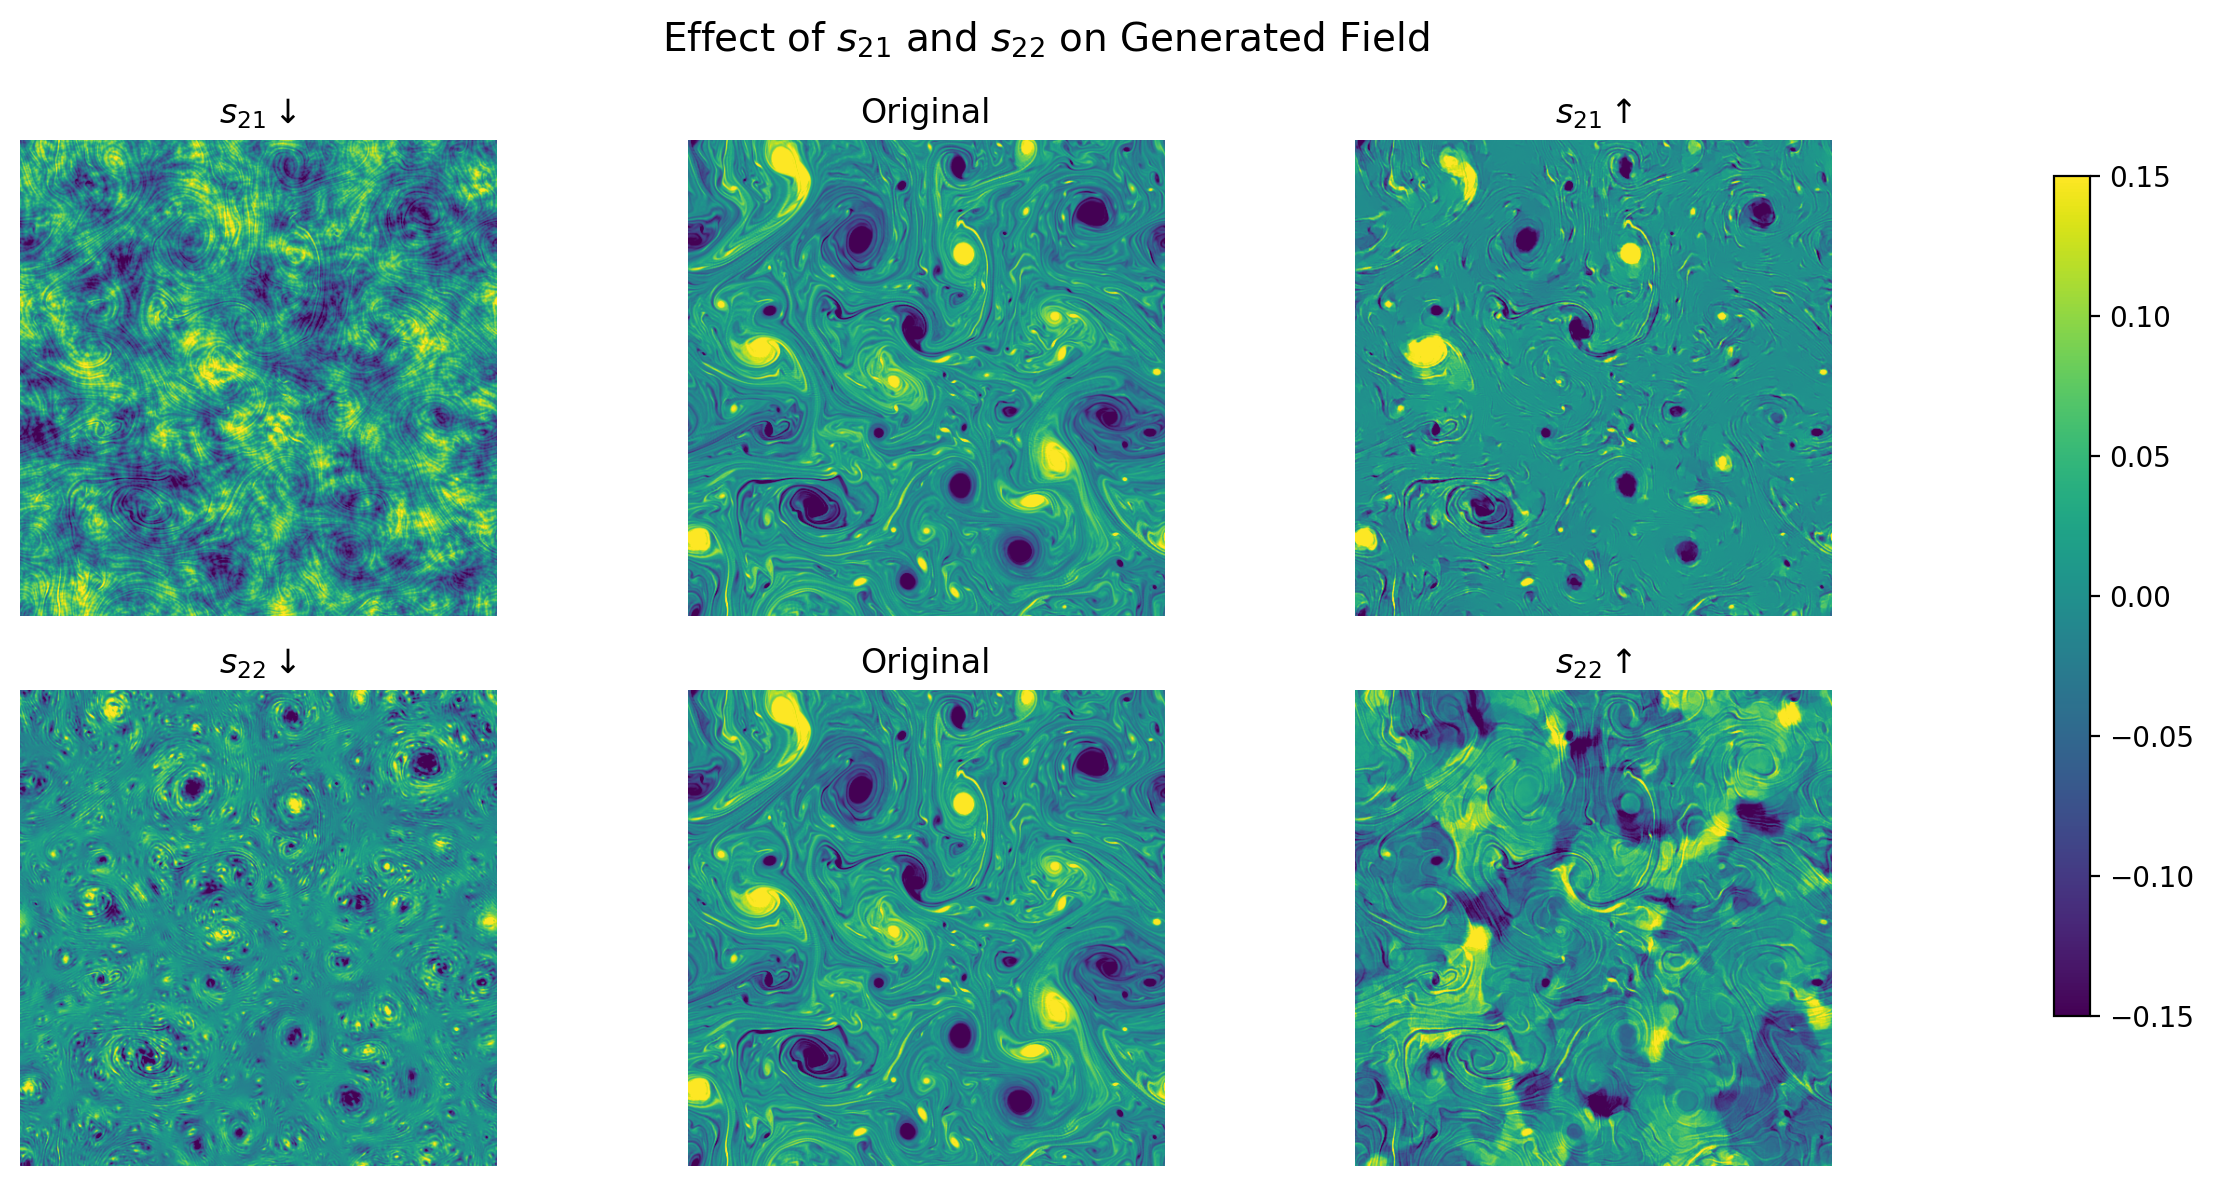

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import cmocean as cmo

def to_numpy(x):
    if hasattr(x, "detach"):  # torch.Tensor
        return x.detach().cpu().numpy()
    return x  # assume already numpy


fields_grid = [
    [optimized_grf_s21low, image[0], optimized_grf_s21high],
    [optimized_grf_s22low, image[0], optimized_grf_s22high]
]

titles_grid = [
    [r"$s_{21} \downarrow$", "Original", r"$s_{21} \uparrow$"],
    [r"$s_{22} \downarrow$", "Original", r"$s_{22} \uparrow$"]
]


# Plot 
vmin = -0.15 #1.3*to_numpy(image[0]).min()
vmax = 0.15 #0.7*to_numpy(image[0]).max()

fig, axes = plt.subplots(2, 3, figsize=(12, 6), dpi=200)
for i in range(2):
    for j in range(3):
        ax = axes[i, j]
        field = to_numpy(fields_grid[i][j])
        im = ax.imshow(field, cmap='viridis', vmin=vmin, vmax=vmax, origin='lower')
        ax.set_title(titles_grid[i][j], fontsize=12)
        ax.axis('off')

cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
fig.colorbar(im, cax=cbar_ax)

fig.suptitle("Effect of $s_{21}$ and $s_{22}$ on Generated Field", fontsize=14)
plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.savefig('scattering_example.png', dpi=300)
plt.show()